# Climate Comfort Index · Random Forest Regressor

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Experiment notebook · predicts CCI +1, +2 and +3 days ahead*

This notebook develops the **Random Forest Regressor** model for the **Climate Comfort Index (CCI)**: pipeline stages 1-2, using the leakage-audited feature matrix produced by the preprocessing notebook.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

### Hypothesis

A Random Forest will **beat persistence and climatology at all three horizons**, because averaging
many decorrelated trees gives low-variance predictions that need little tuning.

The competing possibility is that averaging washes out the weak frontal signal the delta and
pressure features were built to supply, leaving a smoothed climatology. The ablation (section
4) and the prediction spread in the cross-validated results (section 6) test this.

### Design

| Choice | Value | Reason |
|:--|:--|:--|
| Algorithm | `RandomForestRegressor` | Low-variance ensemble with strong defaults on tabular data |
| Scaling | None | Trees split on thresholds, so scale is irrelevant |
| Strategy | One model per horizon (the endpoint returns three values) | Matches the deployed artefact layout |
| Selection | Optuna on walk-forward CV, all features | Section 5 |
| Objective | validation **mean absolute error (MAE)**, in CCI points (lower is better), averaged over the walk-forward folds | Used for every comparison |

### Where this notebook sits in the pipeline

| Stage | What happens | Where |
|:-:|:--|:--|
| 1–2 | Baselines, ablation and hyperparameter tuning on all features | **This notebook** |
| 3 | Shortlist the best tuned algorithms | Comparison notebook |
| 4 | Feature selection for the shortlist, then a short re-tune | Comparison notebook |
| 5–6 | Choose the champion; refit it on all development data | Comparison notebook |
| 7 | Score the champion once on the test split (2025) | Comparison notebook |
| 8 | Deploy with drift monitoring | Promotion + API |

Every score in this notebook is a **walk-forward cross-validation** average: the development split
(2016–2024) is divided into four expanding-window folds that validate on 2021, 2022, 2023 and 2024
in turn, with the embargo as a gap. A setting therefore has to work across four years, not one. The
test split is never loaded here.

### Workflow

All ten experiment notebooks run the same code from `nucleus_ml.weather.Experiment`, so their results are directly comparable. **Only the model specification in section 1 differs between notebooks.**

| # | Step | Purpose |
|:-:|:--|:--|
| 1 | Model specification | The only algorithm-specific cell |
| 2 | Data and folds | The development split and its walk-forward folds |
| 3 | Baselines | Stage 1: the floor every model must clear |
| 4 | Feature-family ablation | What each block of engineered features contributes |
| 5 | Hyperparameter tuning | Stage 2: Optuna, scored by walk-forward CV on all features |
| 6 | Cross-validated results | The model against its default and the baselines |
| 7 | Feature importance | Which features the model relies on |
| 8 | Generalisation check | Training vs validation performance |
| 9 | Save the experiment bundle | Model, CV results and specification |
| 10 | Conclusions | What to carry into the report |

---
## 0. Setup

Imports, the experiment's identity and the task definition. Everything else comes from the project package.

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

from nucleus_ml import CategoricalParameter, FloatParameter, IntParameter
from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "comfort_climate"
EXPERIMENT = "cci_random_forest"
ALGORITHM = "Random Forest Regressor"
VERBOSE = 1  # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit
N_TRIALS = 25  # Optuna trials per target (each trial fits one model per fold)

task = wx.load_task(TASK)
print(f"{task.target_name} | {ALGORITHM} | {len(task.feature_columns)} features | "
      f"targets: {task.target_columns}")

Climate Comfort Index | Random Forest Regressor | 105 features | targets: ['cci_t1', 'cci_t2', 'cci_t3']


---
## 1. Model specification

This is the **only algorithm-specific cell**. It creates the experiment from the estimator class, which the package builds (seeding it and, where requested, scaling the features), so no helper function is needed. It also sets `default_params` (the untuned reference), a cheaper `ablation_params` and the `search_space`, written with the `nucleus_ml` parameter classes.

`max_features` matters most. The feature matrix contains blocks of near-duplicate columns (a
variable, its lags and its rolling means); low values force the trees to differ, which is what
makes bagging work. `min_samples_leaf` is the main complexity control on a dataset this small.

In [14]:
DEFAULT_PARAMS = {"n_estimators": 400, "max_depth": None, "min_samples_leaf": 2,
                  "min_samples_split": 2, "max_features": 0.3}

exp = wx.Experiment(
    task,
    name=EXPERIMENT,
    algorithm=ALGORITHM,
    verbose=VERBOSE,
    estimator=RandomForestRegressor,
    fixed={"n_jobs": -1},
    default_params=DEFAULT_PARAMS,
    ablation_params={**DEFAULT_PARAMS, "n_estimators": 150},
    search_space={
        "n_estimators": IntParameter(150, 600, step=50),
        "max_depth": CategoricalParameter([None, 6, 10, 16, 24]),
        "min_samples_leaf": IntParameter(1, 30),
        "min_samples_split": IntParameter(2, 40),
        "max_features": FloatParameter(0.05, 1.0),
    },
)

[cci_random_forest] loaded 9,099 development rows; 4 walk-forward folds; 105 features; metric mae (lower is better)


---
## 2. Data and folds

Only the **development split** (`train`, 2016–2024) is loaded. The table lists the
walk-forward folds: each trains on every year before its validation year, with the
embargo between them.

> The preprocessing notebook already applied the chronological split, the warm-up
> filter and the embargo before the test period. Nothing is shuffled here.

In [15]:
exp.data_summary()

,train_start,train_end,validate_start,validate_end,train_rows,validate_rows
fold,,,,,,
1,2000-01-31,2020-12-26,2020-12-30,2021-12-29,7636,365
2,2000-01-31,2021-12-26,2021-12-30,2022-12-29,8001,365
3,2000-01-31,2022-12-26,2022-12-30,2023-12-29,8366,365
4,2000-01-31,2023-12-26,2023-12-30,2024-12-28,8731,365


---
## 3. Baselines

Two naive forecasts, refitted on the training years of every fold and scored on its
validation year (the table shows the mean over the folds):

| Baseline | Rule | What it knows |
|:--|:--|:--|
| **Persistence** | Tomorrow's CCI equals today's CCI | The current weather, but not the season |
| **Climatology** | The average CCI for that day of the year | The season, but not the current weather |

A model must beat **both** to be worth deploying: that shows it has combined current conditions
with the seasonal cycle.

In [16]:
exp.run_baselines()

[cci_random_forest] baseline climatology     cci_t1: mean mae = 7.7886
[cci_random_forest] baseline persistence     cci_t1: mean mae = 7.2395
[cci_random_forest] baseline climatology     cci_t2: mean mae = 7.7842
[cci_random_forest] baseline persistence     cci_t2: mean mae = 9.0695
[cci_random_forest] baseline climatology     cci_t3: mean mae = 7.7788
[cci_random_forest] baseline persistence     cci_t3: mean mae = 9.9167


mae   rmse     r2  pred_std
target model                                    
cci_t1 climatology 7.789 10.406  0.002     3.712
       persistence 7.240  9.614  0.142    10.407
cci_t2 climatology 7.784 10.401  0.003     3.700
       persistence 9.069 11.788 -0.295    10.407
cci_t3 climatology 7.779 10.398  0.004     3.701
       persistence 9.917 12.783 -0.529    10.407

---
## 4. Feature-family ablation

Feature families are added **one at a time**, starting from persistence alone, and the model is cross-validated at each step with `ablation_params`. This *measures* what each block of engineering contributes; choosing features happens later, in the comparison notebook. Scores are mean MAE over the folds.

[cci_random_forest] ablation: 9 feature sets x 3 target(s) x 4 folds
[cci_random_forest] ablation persistence only (cci)              cci_t1: mae = 7.3674 (1 features)
[cci_random_forest] ablation persistence only (cci)              cci_t2: mae = 8.6310 (1 features)
[cci_random_forest] ablation persistence only (cci)              cci_t3: mae = 9.0571 (1 features)
[cci_random_forest] ablation + same_day_observations             cci_t1: mae = 6.3972 (6 features)
[cci_random_forest] ablation + same_day_observations             cci_t2: mae = 7.4470 (6 features)
[cci_random_forest] ablation + same_day_observations             cci_t3: mae = 7.7353 (6 features)
[cci_random_forest] ablation + same_day_indices                  cci_t1: mae = 6.4079 (17 features)
[cci_random_forest] ablation + same_day_indices                  cci_t2: mae = 7.5875 (17 features)
[cci_random_forest] ablation + same_day_indices                  cci_t3: mae = 7.8469 (17 features)
[cci_random_forest] ablation + lags  

/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `s

[cci_random_forest] ablation + rolling_gusts                     cci_t2: mae = 7.3792 (97 features)
[cci_random_forest] ablation + rolling_gusts                     cci_t3: mae = 7.6754 (97 features)
[cci_random_forest] ablation + deltas                            cci_t1: mae = 6.2793 (103 features)
[cci_random_forest] ablation + deltas                            cci_t2: mae = 7.3498 (103 features)
[cci_random_forest] ablation + deltas                            cci_t3: mae = 7.6131 (103 features)
[cci_random_forest] ablation + seasonal                          cci_t1: mae = 6.2968 (105 features)
[cci_random_forest] ablation + seasonal                          cci_t2: mae = 7.3805 (105 features)
[cci_random_forest] ablation + seasonal                          cci_t3: mae = 7.6678 (105 features)


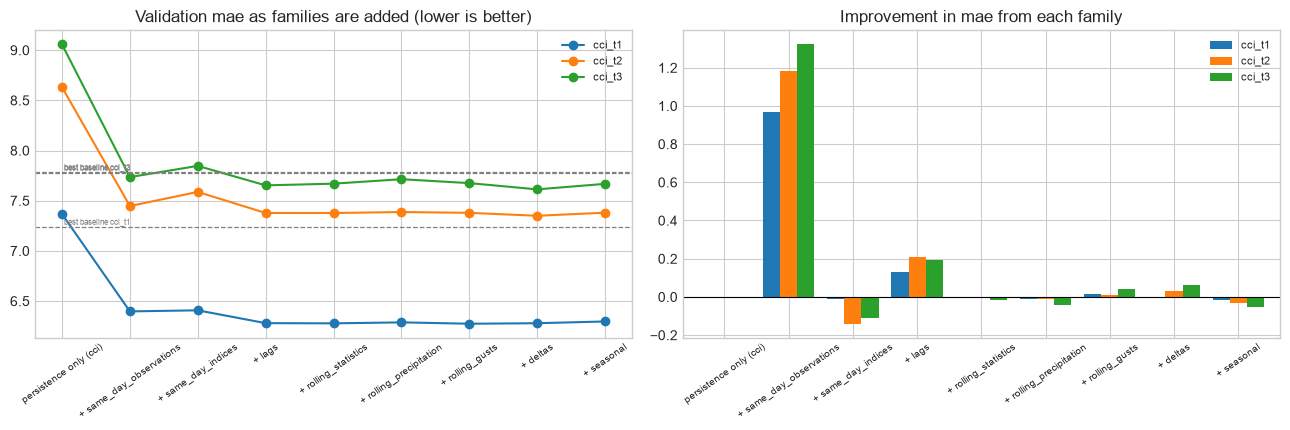

target,cci_t1,cci_t2,cci_t3,n_features
config,,,,
persistence only (cci),7.367,8.631,9.057,1
+ same_day_observations,6.397,7.447,7.735,6
+ same_day_indices,6.408,7.587,7.847,17
+ lags,6.280,7.378,7.653,49
+ rolling_statistics,6.278,7.377,7.670,89
+ rolling_precipitation,6.288,7.387,7.714,93
+ rolling_gusts,6.274,7.379,7.675,97
+ deltas,6.279,7.350,7.613,103
+ seasonal,6.297,7.381,7.668,105


In [17]:
ablation = exp.run_ablation()
plt.show()
ablation

---
## 5. Hyperparameter tuning

Optuna (seeded TPE sampler) searches the space defined in section 1, **on all
features**. Every trial is cross-validated on the four folds and scored by its
mean, so the search cannot overfit to one year. Each target is tuned separately.
The plots show the search history and which settings mattered most.

In [18]:
exp.tune(n_trials=N_TRIALS)

[cci_random_forest] tuning cci_t1: 25 trials x 4 folds


[I 2026-09-19 18:01:27,000] A new study created in memory with name: cci_random_forest_cci_t1
[I 2026-09-19 18:01:48,550] Trial 0 finished with value: 6.2923890579933435 and parameters: {'n_estimators': 150, 'max_depth': 24, 'min_samples_leaf': 3, 'min_samples_split': 14, 'max_features': 0.9789821783658363}. Best is trial 0 with value: 6.2923890579933435.
[I 2026-09-19 18:02:22,566] Trial 1 finished with value: 6.269018100822314 and parameters: {'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 23, 'min_samples_split': 14, 'max_features': 0.7500200810756734}. Best is trial 1 with value: 6.269018100822314.
[I 2026-09-19 18:02:29,431] Trial 2 finished with value: 6.317782408786579 and parameters: {'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 10, 'max_features': 0.14329188458567382}. Best is trial 1 with value: 6.269018100822314.
[I 2026-09-19 18:02:52,882] Trial 3 finished with value: 6.2341214692764275 and parameters: {'n_estimators': 500, 'max

[cci_random_forest] best cci_t1: mean mae = 6.2261 (593s)
[cci_random_forest] tuning cci_t2: 25 trials x 4 folds


[I 2026-09-19 18:11:19,921] A new study created in memory with name: cci_random_forest_cci_t2
[I 2026-09-19 18:11:41,262] Trial 0 finished with value: 7.373547193704001 and parameters: {'n_estimators': 150, 'max_depth': 24, 'min_samples_leaf': 3, 'min_samples_split': 14, 'max_features': 0.9789821783658363}. Best is trial 0 with value: 7.373547193704001.
[I 2026-09-19 18:12:13,760] Trial 1 finished with value: 7.3337939739215905 and parameters: {'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 23, 'min_samples_split': 14, 'max_features': 0.7500200810756734}. Best is trial 1 with value: 7.3337939739215905.
[I 2026-09-19 18:12:20,749] Trial 2 finished with value: 7.341142326248113 and parameters: {'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 10, 'max_features': 0.14329188458567382}. Best is trial 1 with value: 7.3337939739215905.
[I 2026-09-19 18:12:44,521] Trial 3 finished with value: 7.321817363669857 and parameters: {'n_estimators': 500, 'max

[cci_random_forest] best cci_t2: mean mae = 7.3107 (354s)
[cci_random_forest] tuning cci_t3: 25 trials x 4 folds


[I 2026-09-19 18:17:14,343] A new study created in memory with name: cci_random_forest_cci_t3
[I 2026-09-19 18:17:27,441] Trial 0 finished with value: 7.692365411690126 and parameters: {'n_estimators': 150, 'max_depth': 24, 'min_samples_leaf': 3, 'min_samples_split': 14, 'max_features': 0.9789821783658363}. Best is trial 0 with value: 7.692365411690126.
[I 2026-09-19 18:17:46,227] Trial 1 finished with value: 7.623755738425658 and parameters: {'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 23, 'min_samples_split': 14, 'max_features': 0.7500200810756734}. Best is trial 1 with value: 7.623755738425658.
[I 2026-09-19 18:17:50,415] Trial 2 finished with value: 7.583860044491912 and parameters: {'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 3, 'min_samples_split': 10, 'max_features': 0.14329188458567382}. Best is trial 2 with value: 7.583860044491912.
[I 2026-09-19 18:18:04,357] Trial 3 finished with value: 7.643442102365087 and parameters: {'n_estimators': 500, 'max_de

[cci_random_forest] best cci_t3: mean mae = 7.5703 (197s)


,cv_mae,trials,best_params
target,,,
cci_t1,6.226,25,"{'n_estimators': 150, 'max_depth': 24, 'min_sa..."
cci_t2,7.311,25,"{'n_estimators': 600, 'max_depth': 16, 'min_sa..."
cci_t3,7.570,25,"{'n_estimators': 350, 'max_depth': 10, 'min_sa..."


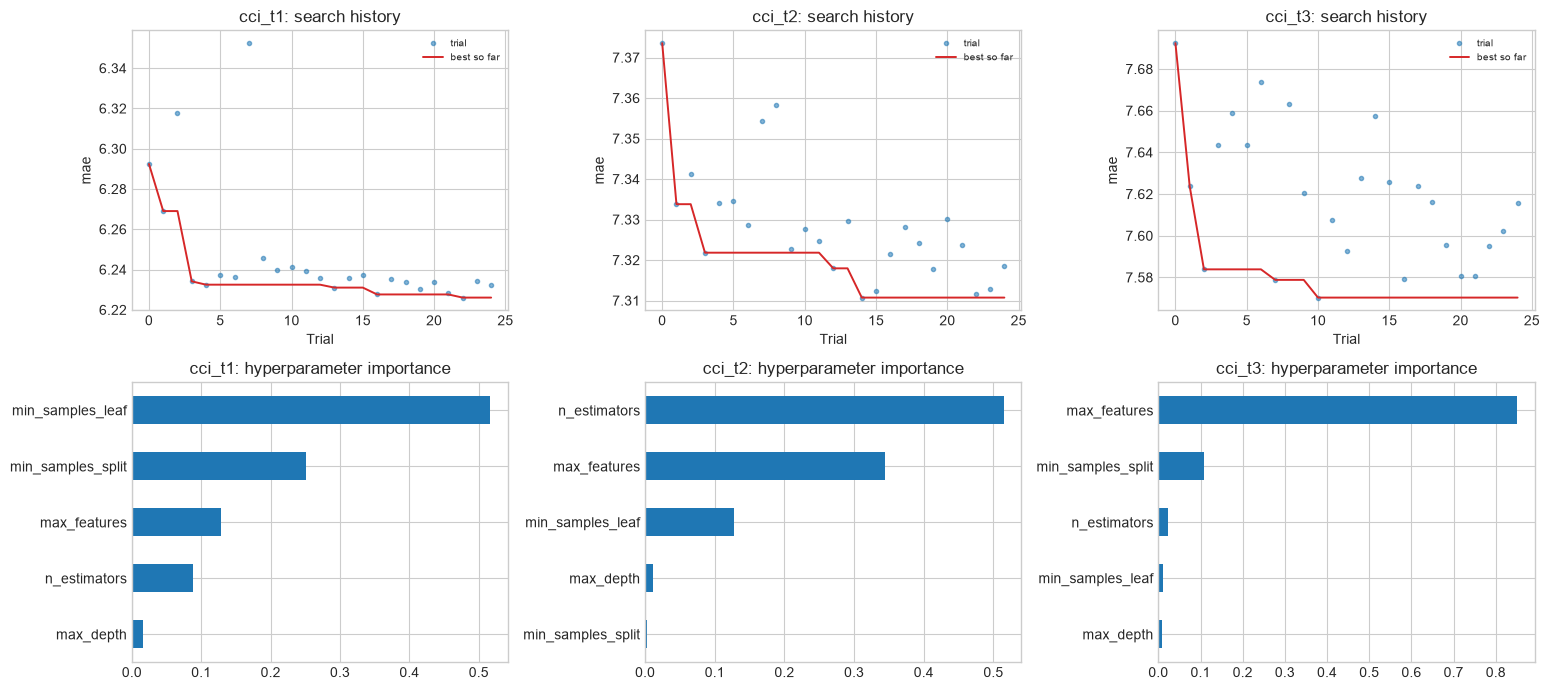

In [19]:
exp.plot_search()
plt.show()

---
## 6. Cross-validated results

The chosen configuration is cross-validated again and compared with the untuned `default` and every baseline, all on the same folds. `gain_of_model` is positive when the model beats that row. The plot shows the **out-of-fold predictions**: every validation year predicted by a model that never saw it.

`pred_std` is shown next to the error metrics. A spread far below the observed spread means the
model is playing safe by predicting close to the average, which can give a respectable MAE while
missing exactly the uncomfortable days users care about. Expect error to grow with the horizon.

In [20]:
exp.assess()

[cci_random_forest] assess cci_t1: tuned mean mae = 6.2261 (best baseline 7.2395)
[cci_random_forest] assess cci_t2: tuned mean mae = 7.3107 (best baseline 7.7842)
[cci_random_forest] assess cci_t3: tuned mean mae = 7.5703 (best baseline 7.7788)


mae   rmse     r2  pred_std  train_mae  gain_of_model
target model                                                              
cci_t1 climatology 7.789 10.406  0.002     3.712        NaN          1.563
       default     6.268  8.401  0.347     6.141      2.356          0.041
       persistence 7.240  9.614  0.142    10.407        NaN          1.013
       tuned       6.226  8.358  0.353     6.221      4.804         -0.000
cci_t2 climatology 7.784 10.401  0.003     3.700        NaN          0.474
       default     7.358  9.706  0.127     4.492      2.634          0.048
       persistence 9.069 11.788 -0.295    10.407        NaN          1.759
       tuned       7.311  9.678  0.133     4.395      5.787         -0.000
cci_t3 climatology 7.779 10.398  0.004     3.701        NaN          0.208
       default     7.660 10.059  0.065     4.222      2.631          0.090
       persistence 9.917 12.783 -0.529    10.407        NaN          2.346
       tuned       7.570 10.025  0.072     3.827      6.333         -0.000

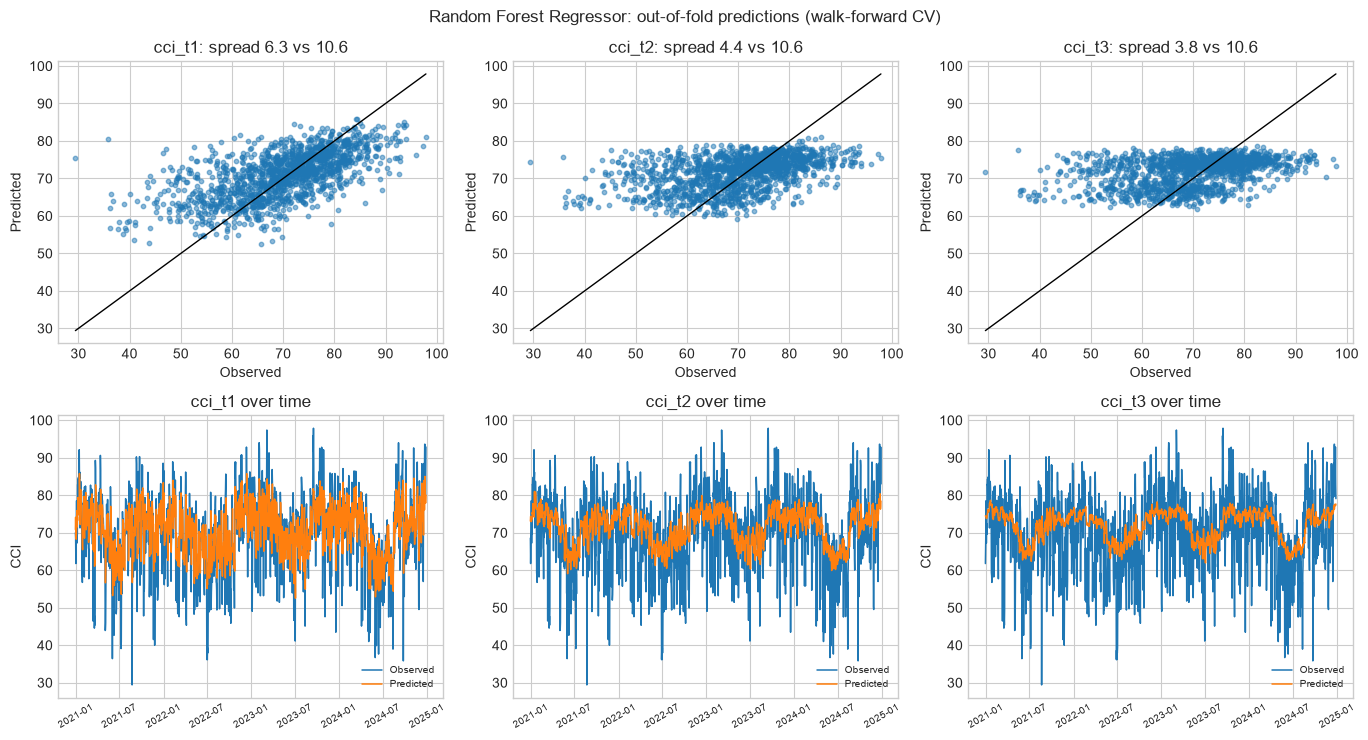

In [21]:
exp.plot_validation()
plt.show()

---
## 7. Feature importance

Tree ensembles report **impurity-based importance** directly from the fitted model. Comparing horizons is informative: features that rise in rank from *t*+1 to *t*+3 carry genuine forecast signal rather than persistence.

> Importance is measured on the last fold's model and validation year (2024). Correlated features share importance, so the ablation in section 4 is the better guide to what can be removed.

[cci_random_forest] computing feature importance (permutation importance can take a while)


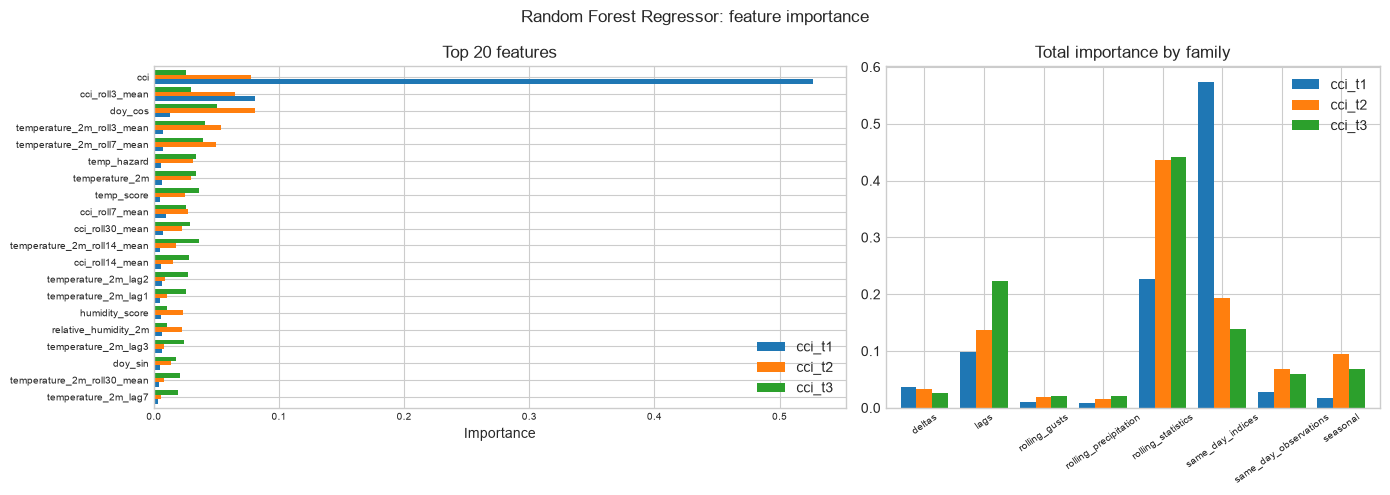

,cci_t1,cci_t2,cci_t3
deltas,0.037,0.033,0.026
lags,0.099,0.137,0.224
rolling_gusts,0.010,0.020,0.021
rolling_precipitation,0.009,0.016,0.021
rolling_statistics,0.227,0.437,0.441
same_day_indices,0.573,0.194,0.139
same_day_observations,0.028,0.069,0.060
seasonal,0.017,0.094,0.068


In [22]:
family_importance = exp.importance()
plt.show()
family_importance

---
## 8. Generalisation check

Mean training and validation scores over the folds. A small gap means the model
generalises; a large gap means it memorises the training years.

In [23]:
exp.generalisation()

,train_mae,validation_mae,validation_minus_train
target,,,
cci_t1,4.804,6.226,1.422
cci_t2,5.787,7.311,1.524
cci_t3,6.333,7.570,1.238


---
## 9. Save the experiment bundle

The chosen configuration is refitted on **all development data** and saved to
`models/comfort_climate/experiments/cci_random_forest/`:

| File | Contents |
|:--|:--|
| `cci_random_forest_h<horizon>.joblib` | The model, one per horizon |
| `metadata.json` | Settings, features, importance and the cross-validated scores |
| `manifest.json` | File list and the feature column order |
| `spec.joblib` | The specification and tuned settings, which the comparison notebook uses to rebuild this experiment |

In [24]:
exp.export()

[cci_random_forest] final fit cci_t1: 9,099 rows, 105 features
[cci_random_forest] final fit cci_t2: 9,099 rows, 105 features
[cci_random_forest] final fit cci_t3: 9,099 rows, 105 features
Saved bundle: models/comfort_climate/experiments/cci_random_forest


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/models/comfort_climate/experiments/cci_random_forest')

---
## 10. Conclusions

- **Against the baselines.** Beating persistence at *t*+1 is the hardest test, because
  persistence is strongest at short lead times.
- **Spread.** Averaging hundreds of trees makes `pred_std` fall below the observed spread;
  report how far, because it limits how well the endpoint can flag uncomfortable days.
- **Which families the forest uses.** Compare the ablation with the importance-by-family chart.

> If this algorithm is shortlisted, the comparison notebook selects its feature families with walk-forward cross-validation and briefly re-tunes its settings on the chosen features.

> The test split has still not been used. It is scored exactly once, in the `cci_comparison` notebook, after the champion has been chosen.